# Fixed Income Risk Dashboard
### Task 03 · P&L Explain & Exception Monitoring

**Rates Desk Analytics** · Python / NumPy / pandas · C# / ClosedXML · Excel

> **Business question:** Does the reported daily P&L agree with what yesterday's positions and today's interest-rate moves predict? If not, is the difference unusual *for this book's current risk*?

### Results at a glance

| Measure | Verified lab result |
|:--|--:|
| Reporting observations | **518 days** (258 in 2023; 260 in 2024) |
| 2023 fitted mark-noise scale | **0.0963 bp per curve vertex** |
| 2023 RMS unexplained P&L — risk-based model | **USD 16,615** |
| 2024 fixed-threshold exceptions (3.5 sigma) | **49 days** |
| 2024 risk-scaled exceptions (3.5 sigma) | **34 days** |
| Largest 2024 absolute Z-score | **78.0** on **2024-11-20** |

The focus is **P&L explanation and screening**, not proof of a booking error. All source positions and market data belong to an **educational simulated desk**.

**Project provenance:** Based on the [RiskHub Fixed Income Risk Dashboard Python Lab](https://riskhub.org/python-labs/fixed-income-risk-dashboard), with this notebook's explanation, validation and C# Excel reporting workflow organized for a portfolio presentation.

---

## 01 · Workflow & analytical scope

This module builds on Tasks 1–2. It uses the reconstructed bond book and previous-day Key-Rate DV01 to compare an **independent P&L estimate** with the desk's externally reported P&L.

| Step | Inputs | Output / desk use |
|:--|:--|:--|
| 1. Book and curve | Trade amendments, zero curves, coupons | Consistent closing and prior-day positions |
| 2. Carry | Prior positions, aged bond values, cash payments | Time-related P&L |
| 3. Market explain | Yesterday's DV01 ladder, today's curve changes | First-order market P&L |
| 4. Reconcile | Reported P&L vs estimated P&L | Unexplained residual |
| 5. Scale and screen | 2023 residual calibration, current risk ladder | Z-score and 2024 exception flags |
| 6. Deliver | Daily series, 11 tenor contributions | C#-generated interactive Excel workbook |

**Model boundary:** This is an end-of-day *risk-based approximation*. It is not an official ledger reconciliation or a full trade-level P&L explain.

## 02 · Market data and reporting calendar

The exercise feed contains continuously compounded zero yields (percent), one reported desk P&L field (USD), and business dates from 2020-12-31 through 2024-12-31. The 11 curve vertices run from 3M to 30Y.

**Portability:** `DataSource/rates_desk_feed.csv` is intentionally excluded from GitHub. The code resolves the repository root from either the `RAD_RISK_ROOT` environment variable or a parent directory containing the feed, so the Notebook can run from `Task3_Pnl_Explain/`.

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if os.environ.get("RAD_RISK_ROOT"):
    BASE_DIR = Path(os.environ["RAD_RISK_ROOT"]).expanduser().resolve()
else:
    current = Path.cwd().resolve()
    BASE_DIR = next(
        (p for p in (current, *current.parents)
         if (p / "DataSource" / "rates_desk_feed.csv").is_file()),
        current,
    )

DATA_FILE = BASE_DIR / "DataSource" / "rates_desk_feed.csv"
if not DATA_FILE.is_file():
    raise FileNotFoundError(
        f"Input feed not found: {DATA_FILE}. "
        "Place the authorized lab CSV in DataSource/ or set RAD_RISK_ROOT."
    )

df = pd.read_csv(DATA_FILE, parse_dates=["date"], index_col="date")
DATES = df.index
LAB = [column[2:] for column in df.columns if column.startswith("Z_")]
TEN = np.array([0.25, 0.5, 1, 2, 3, 5, 7, 10, 15, 20, 30])
Z = df[["Z_" + tenor for tenor in LAB]].to_numpy()
PNL = df["PNL_REPORTED"].to_numpy()
REP = np.where(DATES >= "2023-01-03")[0]

assert len(LAB) == len(TEN) == 11
assert len(REP) == 518
print(f"Market dates: {DATES[0].date()} to {DATES[-1].date()}")
print(f"Report mornings: {len(REP)} | Curve tenors: {', '.join(LAB)}")

Market dates: 2020-12-31 to 2024-12-31
Report mornings: 518 | Curve tenors: 3M, 6M, 1Y, 2Y, 3Y, 5Y, 7Y, 10Y, 15Y, 20Y, 30Y


## 03 · Portfolio reconstruction from the trade blotter

The book contains 19 defined government bond instruments with semiannual coupons; **active positions change by date**. The trade blotter includes replacements/amendments: for example, ticket `T019` is amended in April 2024 and `T021` in June 2024.

A previously booked ticket is **replaced by its later amendment** rather than counted as another independent trade. Position signs preserve long/short exposure.

In [2]:
BONDS = {   # bond: (coupon % a year, paid twice a year, maturity date)
    'GOV_23': (0.875, '2023-09-30'), 'GOV_24': (1.500, '2024-05-15'), 'GOV_25': (2.750, '2025-08-15'),
    'GOV_26': (4.125, '2026-06-15'), 'GOV_27': (3.250, '2027-11-15'), 'GOV_27B': (4.500, '2027-05-15'),
    'GOV_28': (4.000, '2028-05-15'), 'GOV_29': (3.750, '2029-02-15'), 'GOV_29B': (4.000, '2029-08-15'),
    'GOV_30': (4.000, '2030-02-15'), 'GOV_31': (4.125, '2031-08-15'), 'GOV_32': (2.875, '2032-05-15'),
    'GOV_33': (3.500, '2033-02-15'), 'GOV_34': (4.250, '2034-02-15'), 'GOV_37': (4.000, '2037-11-15'),
    'GOV_42': (3.250, '2042-08-15'), 'GOV_44': (4.375, '2044-02-15'), 'GOV_52': (3.000, '2052-08-15'),
    'GOV_53': (4.125, '2053-08-15'),
}
IDS = list(BONDS)
BLOTTER = [   # the risk system's trade blotter: (ticket, booked, traded, bond, face USD m: + bought / - sold)
    ('T001', '2022-12-30', '2022-12-30', 'GOV_23', 70), ('T002', '2022-12-30', '2022-12-30', 'GOV_24', 60),
    ('T003', '2022-12-30', '2022-12-30', 'GOV_25', 80), ('T004', '2022-12-30', '2022-12-30', 'GOV_27', 150),
    ('T005', '2022-12-30', '2022-12-30', 'GOV_29', 90), ('T006', '2022-12-30', '2022-12-30', 'GOV_32', -120),
    ('T007', '2022-12-30', '2022-12-30', 'GOV_33', -60), ('T008', '2022-12-30', '2022-12-30', 'GOV_37', 40),
    ('T009', '2022-12-30', '2022-12-30', 'GOV_42', -50), ('T010', '2022-12-30', '2022-12-30', 'GOV_52', 35),
    ('T011', '2023-02-14', '2023-02-14', 'GOV_26', 50), ('T012', '2023-04-20', '2023-04-20', 'GOV_32', 40),
    ('T013', '2023-06-07', '2023-06-07', 'GOV_30', 70), ('T014', '2023-08-23', '2023-08-23', 'GOV_44', -30),
    ('T015', '2023-10-11', '2023-10-11', 'GOV_27', -50), ('T016', '2023-11-29', '2023-11-29', 'GOV_53', 25),
    ('T017', '2024-01-17', '2024-01-17', 'GOV_25', -40), ('T018', '2024-02-21', '2024-02-21', 'GOV_30', 30),
    ('T019', '2024-04-10', '2024-04-10', 'GOV_34', 50), ('T019', '2024-04-16', '2024-04-10', 'GOV_34', -50),
    ('T020', '2024-05-22', '2024-05-22', 'GOV_42', 20),
    ('T021', '2024-06-12', '2024-06-12', 'GOV_27B', 40), ('T021', '2024-06-26', '2024-06-12', 'GOV_27B', 4),
    ('T022', '2024-08-07', '2024-08-07', 'GOV_44', 15),
    ('T026', '2024-08-21', '2024-08-21', 'GOV_28', 260), ('T027', '2024-08-21', '2024-08-21', 'GOV_31', -170),
    ('T023', '2024-09-12', '2024-09-09', 'GOV_29B', 8),
    ('T025', '2024-12-04', '2024-12-04', 'GOV_26', -20),
]   # a ticket that appears twice was AMENDED: its later row replaces the earlier one from that booked date
VAR_DAYS, VAR_K = 500, 5    # 1-day 99% HS VaR: the 5th worst of the last 500 daily curve moves (1% of 500)

print(f"Bond definitions: {len(IDS)} | Blotter rows: {len(BLOTTER)}")

Bond definitions: 19 | Blotter rows: 28


## 04 · Bond cash flows and zero-curve interpolation

For each fixed-rate bond, the model generates future semiannual coupon payments and principal at maturity. Zero yields are interpolated linearly between the 11 market vertices and held flat outside the defined tenor range.

The valuation convention is **continuous compounding** on an ACT/365-style year fraction, consistent with the underlying lab. Scheduled coupon dates are unadjusted for holidays/weekends.

In [3]:
def cash_flows(bond):
    """Done for you: the bond's payment dates after the data starts (every 6 months back from maturity, unadjusted)
    and its payments per 100 face: coupon / 2 on each date, + 100 at maturity."""
    cpn, mat = BONDS[bond]
    mat = pd.Timestamp(mat)
    dates = pd.DatetimeIndex([mat - pd.DateOffset(months=6 * k) for k in range(80)][::-1])
    dates = dates[dates > DATES[0]]
    cf = np.full(len(dates), cpn / 2)
    cf[-1] += 100.0
    return dates, cf


def interp_weights(tau):
    """Done for you: weights W (shape tau.shape + (11,)) with W @ curve = the zero rate at each tau, linear between
    vertices and flat beyond the first and last. Each row has at most two non-zero weights, summing to 1."""
    tc = np.clip(tau, TEN[0], TEN[-1])
    j = np.clip(np.searchsorted(TEN, tc, side='right') - 1, 0, len(TEN) - 2)
    a = (tc - TEN[j]) / (TEN[j + 1] - TEN[j])
    W = np.zeros(np.shape(tau) + (len(TEN),))
    np.put_along_axis(W, j[..., None], (1 - a)[..., None], axis=-1)
    W2 = np.zeros_like(W)
    np.put_along_axis(W2, (j + 1)[..., None], a[..., None], axis=-1)
    return W + W2

## 05 · Historical positions and valuation arrays

`positions_history()` builds the full daily positions matrix. The multiplier `UNIT = 10,000` converts the exercise's *USD millions of face* and *price per 100 face* into USD position value and DV01 units.

`history()` prepares five per-bond arrays used in the explain:

| Array | Meaning |
|:--|:--|
| `V` | Today's bond value, on today's curve |
| `VA` | Today's aged bond value, using yesterday's curve |
| `K` | Today's key-rate sensitivity ladder |
| `KA` | Aged sensitivity, still using yesterday's curve |
| `CASH` | Coupons or principal paid since the prior report |

**Important:** The P&L explain below uses **yesterday's positions**, not today's amended book. It therefore does not purport to explain trading P&L from new positions or execution prices.

In [4]:
def positions_history(blotter=BLOTTER):
    """Done for you (Task 1's book_on, for every day at once): the position in each bond (days x bonds, USD m
    face) at each close. Each blotter row changes its ticket's face from that row's booked date onwards."""
    b = pd.DataFrame(blotter, columns=['ticket', 'booked', 'traded', 'bond', 'face'])
    step = b['face'] - b.groupby('ticket')['face'].shift(1).fillna(0)
    Q = np.zeros((len(DATES), len(IDS)))
    for r, bond, s in zip(DATES.searchsorted(pd.to_datetime(b['booked'])), b['bond'], step):
        Q[r:, IDS.index(bond)] += s
    return Q

def history(curves):
    """Done for you (Task 1's price_and_ladder, for every day and bond at once). Per 100 face, rows = days, columns =
    bonds: V = value off curve t on day t; VA = value off curve t-1 on day t (the bond one day OLDER, on YESTERDAY's
    curve); K, KA = the key-rate ladders of the same two (days x bonds x 11); CASH = what the bond paid in (t-1, t]."""
    prev = np.vstack([curves[:1], curves[:-1]])
    out = {k: [] for k in ('V', 'VA', 'K', 'KA', 'CASH')}
    for bond in IDS:
        dates, cf = cash_flows(bond)
        tau = (dates.values[None, :] - DATES.values[:, None]) / np.timedelta64(1, 'D') / 365.0
        live = tau > 0
        W = interp_weights(np.where(live, tau, 1.0))
        for name, C in (('', curves), ('A', prev)):
            dfac = np.where(live, np.exp(-np.einsum('nmk,nk->nm', W, C) / 100 * tau), 0.0)
            out['V' + name].append(dfac @ cf)
            out['K' + name].append(np.einsum('nm,nmk->nk', dfac * cf * tau, W) * 1e-4)
        paid = (dates.values[None, :] > DATES.values[:-1, None]) & (dates.values[None, :] <= DATES.values[1:, None])
        out['CASH'].append(np.concatenate([[0.0], paid.astype(float) @ cf]))
    return {k: np.stack(v, axis=1) for k, v in out.items()}


UNIT = 1e4    # USD per (USD m face x price per 100): a position's USD value = face x UNIT x value per 100

## 06 · Carry / time P&L

Carry here means the change caused by advancing the valuation date while **holding yesterday's positions and curve fixed**, including bond cash payments during the interval.

$$
\mathrm{Carry}_t
=\sum_b Q_{t-1,b}\left(V^A_{t,b}+\mathrm{Cash}_{t,b}-V_{t-1,b}\right)
$$

In this exercise the carry component includes coupon accrual / time decay under the lab's valuation convention. It is **not** a standalone financing or funding-cost calculation.

In [5]:
def carry(Q, V, VA, CASH):
    """TODO: The walk's time step for VALUE, every morning (USD): yesterday's positions one day older on yesterday's
    curve, plus the cash they paid out (coupons, principal), minus yesterday's value.
    Qp = Q shifted down a row (row 0 is its own yesterday), Vp likewise; carry = sum over bonds of Qp x (VA + CASH - Vp)."""
    Qp = np.vstack([Q[:1], Q[:-1]])
    Vp = np.vstack([V[:1], V[:-1]])

    return np.sum(
        Qp * (VA + CASH - Vp),
        axis=1
    )

## 07 · Market P&L and risk-based prediction

A curve shock is measured in **basis points (bp)**. A positive Key-Rate DV01 represents an approximate gain for a 1 bp **fall** at that vertex, so an upward yield move gives a negative first-order contribution.

$$
\mathrm{MarketP\&L}_{t}^{\mathrm{linear}}
=-\sum_{k=1}^{11}\mathrm{DV01}_{t-1,k}\,\Delta y_{t,k}
$$

$$
\mathrm{PredictedP\&L}_{t}
=\mathrm{Carry}_t+\mathrm{MarketP\&L}_{t}^{\mathrm{linear}}
$$

The previous-day ladder is frozen when attributing today's rate movement. This is a **linear sensitivity approximation**, not a full nonlinear revaluation.

In [6]:
def predicted_pnl(carry_, L_prev, moves):
    """TODO: The risk-based P&L every morning: carry + what yesterday's ladder says the curve move made,
    -sum(L_prev x moves) over the 11 vertices (moves in bp, L_prev in USD per bp)."""
    return carry_ - np.sum(L_prev * moves, axis=1)

## 08 · Unexplained P&L and risk-scaled noise

The gap between the desk's reported daily P&L and the model estimate is the **unexplained P&L**:

$$
U_t=\mathrm{ReportedP\&L}_t-\mathrm{PredictedP\&L}_t
$$

To separate an expected mark difference from a potentially unusual residual, the lab assumes independent vertex-level mark noise of standard deviation $s$ bp **on each date**. Noise in the *difference* of two dates has a $\sqrt{2}$ factor:

$$
\sigma_{U,t}=\sqrt{2}\;s\sqrt{\sum_{k=1}^{11}\mathrm{DV01}_{t-1,k}^{2}}
$$

$$
Z_t=\frac{U_t}{\sigma_{U,t}}
$$

**Calibration / assessment separation:** Estimate the noise parameter using **2023 only**, then apply the fitted parameter unchanged to the **2024** monitoring period. The interpretation relies on this simplifying statistical noise model, not an independently verified production distribution.

In [7]:
def noise_sd(L_prev, s):
    """TODO: The unexplained P&L to expect from mark differences ALONE (USD): if the P&L system's curve differs from the
    feed by independent noise of s bp at each vertex each day, a day's move differs by sqrt(2) s, so the gap has
    sd sqrt(2) x s x sqrt(sum of L_prev squared)."""
    return (
        np.sqrt(2)
        * s
        * np.sqrt(np.sum(L_prev ** 2, axis=1))
    )

## 09 · Build and validate the daily explain

Reconstruct all historical values, carry and DV01 exposures once, then produce the daily reported, predicted and unexplained P&L arrays. The independent full-revaluation proxy holds **yesterday's book** fixed and revalues it on today's curve; it helps separate *data differences* from *first-order model approximation differences*.

**Consistency checks:** The predicted P&L must equal carry plus the linear 11-tenor market explain. The two residual components must add back to total unexplained P&L.

In [8]:
# Position, valuation and curve-move history
H = history(Z)
Q = positions_history() * UNIT
moves = np.vstack([np.zeros((1, 11)), np.diff(Z, axis=0) * 100])
Qp = np.vstack([Q[:1], Q[:-1]])
L_prev = np.einsum(
    "nb,nbk->nk",
    Qp,
    np.vstack([H["K"][:1], H["K"][:-1]]),
)

# Preserve the original lab's model definitions
c = carry(Q, H["V"], H["VA"], H["CASH"])
full = c + (Qp * (H["V"] - H["VA"])).sum(axis=1)
pred = predicted_pnl(c, L_prev, moves)
U = PNL - pred
rms = lambda x: float(np.sqrt(np.mean(np.square(x))))
y23 = REP[DATES[REP].year == 2023]
y24 = REP[DATES[REP].year == 2024]

market_linear = -(L_prev * moves).sum(axis=1)
data_gap = PNL - full
model_gap = full - pred

assert len(y23) == 258 and len(y24) == 260
assert np.isfinite(PNL[REP]).all()
assert np.allclose(pred[REP], c[REP] + market_linear[REP], atol=1e-7)
assert np.allclose(U[REP], (data_gap + model_gap)[REP], atol=1e-7)
print("PASS | 518 daily predictions and residuals reconciled")

PASS | 518 daily predictions and residuals reconciled


## 10 · Does including carry improve the P&L explain?

### 10.1 Out-of-sample monitoring needs a credible baseline

Before fitting noise, examine model quality on **2023 calibration data**. The no-carry approximation leaves a large systematic gap. Including carry sharply improves the RMS unexplained P&L. Full revaluation improves it slightly further, consistent with a residual first-order linearization error.

| 2023 comparison | RMS unexplained P&L (USD) |
|:--|--:|
| DV01 × curve move, **without** carry | **74,011** |
| Carry + DV01 × curve move | **16,615** |
| Carry + full curve revaluation proxy | **16,161** |

The reported daily P&L itself has an RMS magnitude of **USD 517,683**; the 2023 mean reported P&L is **USD +23,127**. The two RMS values should not be interpreted as portfolio profitability or forecast performance.

In [9]:
comparison = pd.DataFrame([
    ("DV01 market explain only", float(np.mean((PNL-(pred-c))[y23])), rms((PNL-(pred-c))[y23])),
    ("Carry + DV01 market explain", float(np.mean(U[y23])), rms(U[y23])),
    ("Full revaluation proxy", float(np.mean((PNL-full)[y23])), rms((PNL-full)[y23])),
], columns=["2023 model", "Mean residual (USD)", "RMS residual (USD)"])

print(f"2023 reported P&L: mean USD {PNL[y23].mean():+,.0f} | RMS USD {rms(PNL[y23]):,.0f}")
print(f"Mean daily carry: USD {c[y23].mean():+,.0f}")
display(comparison.style.format({
    "Mean residual (USD)": "{:+,.0f}",
    "RMS residual (USD)": "{:,.0f}",
}))

print(f"Data gap RMS (reported minus full): USD {rms(data_gap[y23]):,.0f}")
print(f"Model gap RMS (full minus linear): USD {rms(model_gap[y23]):,.0f}")

2023 reported P&L: mean USD +23,127 | RMS USD 517,683
Mean daily carry: USD +61,217


,2023 model,Mean residual (USD),RMS residual (USD)
0,DV01 market explain only,"+62,056","74,011"
1,Carry + DV01 market explain,+839,"16,615"
2,Full revaluation proxy,+13,"16,161"


Data gap RMS (reported minus full): USD 16,161
Model gap RMS (full minus linear): USD 3,128


## 11 · Calibrate the 2023 noise model

The fitted vertex-level mark-noise parameter is **0.0963 bp**, estimated from the 2023 unexplained P&L and the portfolio's historical squared DV01 exposure.

$$
\widehat s
=\frac{\operatorname{Std}(U_{2023})}{\sqrt{2\;\operatorname{Mean}(\sum_k\mathrm{DV01}_{t-1,k}^2)}}
$$

This single parameter is carried into 2024 **without refitting**. The standardized 2023 residuals have sample standard deviation approximately **1.000**, by construction of this calibration.

In [10]:
g2 = np.sqrt((L_prev ** 2).sum(axis=1))
s = float(np.std(U[y23]) / np.sqrt(2 * np.mean(g2[y23] ** 2)))
noise = noise_sd(L_prev, s)
z = U / noise

print(f"Fitted noise: s = {s:.4f} bp per vertex")
print(f"2023 standardized residual SD: {np.std(z[y23]):.3f}")
print(f"2024 Q1 standardized residual SD: {np.std(z[y24[:62]]):.3f}")
print(f"Average 2023 expected noise SD: USD {noise[y23].mean():,.0f}")
after_aug = DATES[REP] >= "2024-08-22"
print(f"After 2024-08-21 book expansion: USD {noise[REP][after_aug].mean():,.0f}")

Fitted noise: s = 0.0963 bp per vertex
2023 standardized residual SD: 1.000
2024 Q1 standardized residual SD: 1.124
Average 2023 expected noise SD: USD 16,494
After 2024-08-21 book expansion: USD 26,543


## 12 · Exception screening: fixed vs risk-scaled

A simple fixed limit uses the 2023 overall residual standard deviation. A risk-scaled limit adjusts **daily** for changes in the portfolio's Key-Rate DV01 magnitude.

$$
\text{Fixed flag}_t:\quad |U_t|>3.5\;\operatorname{Std}(U_{2023})
$$

$$
\text{Scaled flag}_t:\quad |Z_t|>3.5
$$

| 2024 outcome | Number of days |
|:--|--:|
| Fixed USD threshold | **49** |
| Risk-scaled Z-score threshold | **34** |
| Flagged by fixed but **not** scaled | **15** |
| Flagged by scaled but **not** fixed | **0** |

**Interpretation:** When the book's DV01 concentration grows, expected mark-to-market noise also grows under the model. The risk-scaled control avoids some fixed-limit flags without asserting those 15 observations were harmless. An extreme Z-score is a **review trigger**, not an incident classification.

In [11]:
THRESHOLD = 3.5
fixed_limit = THRESHOLD * np.std(U[y23])
fixed_flags = np.abs(U[y24]) > fixed_limit
scaled_flags = np.abs(z[y24]) > THRESHOLD

print(f"2024 fixed limit: USD {fixed_limit:,.0f}")
print(f"Fixed flags: {fixed_flags.sum()} | Scaled flags: {scaled_flags.sum()}")
print(f"Fixed-only flags: {(fixed_flags & ~scaled_flags).sum()} | Scaled-only flags: {(scaled_flags & ~fixed_flags).sum()}")
print(f"Largest |Z|: {np.max(np.abs(z[y24])):.1f} on {DATES[y24][np.argmax(np.abs(z[y24]))].date()}")
print(f"2023 in-sample |Z| > 3.5: {(np.abs(z[y23]) > THRESHOLD).sum()}/{len(y23)}")

monthly = pd.DataFrame({
    "Fixed": fixed_flags.astype(int),
    "Scaled": scaled_flags.astype(int),
}, index=DATES[y24]).groupby(DATES[y24].month).sum()
monthly.index.name = "2024 month"
display(monthly.T.rename_axis("Screening policy"))

2024 fixed limit: USD 58,079
Fixed flags: 49 | Scaled flags: 34
Fixed-only flags: 15 | Scaled-only flags: 0
Largest |Z|: 78.0 on 2024-11-20
2023 in-sample |Z| > 3.5: 1/258


2024 month,1,2,3,4,5,6,7,8,9,10,11,12
Screening policy,,,,,,,,,,,,
Fixed,0,0,0,3,0,1,0,0,4,10,16,15
Scaled,0,0,0,3,0,1,0,0,0,6,15,9


### 12.1 Visualize residual severity in units of expected noise

The chart plots standardized unexplained P&L for each 2024 report morning. Orange lines mark the ±3.5 screening thresholds; red marks indicate observations outside that band.

**Important visualization limit:** Values are **clipped at ±12 for display only**. The actual Z-scores and exception counts use the **unclipped** series. The largest absolute 2024 Z-score is approximately **78.0** on **2024-11-20**.

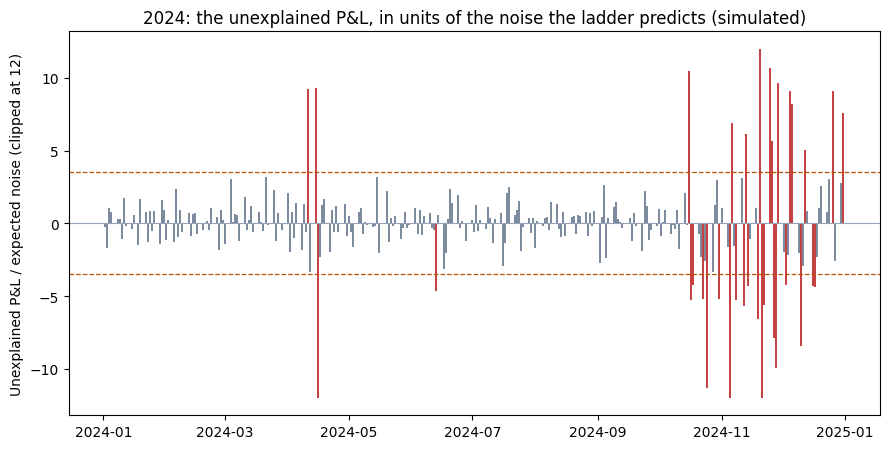

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.6))
zz = np.clip(z[y24], -12, 12)
ax.vlines(DATES[y24], 0, zz, color=np.where(np.abs(z[y24]) > 3.5, '#b91c1c', '#64748b'), lw=1.2)
for h in (-3.5, 3.5):
    ax.axhline(h, color='#b45309', lw=0.9, ls='--')
ax.axhline(0, color='#94a3b8', lw=0.8)
ax.set_ylabel('Unexplained P&L / expected noise (clipped at 12)')
ax.set_title('2024: the unexplained P&L, in units of the noise the ladder predicts (simulated)')
plt.tight_layout()
plt.show()

## 13 · Investigation framing and controls

### 13.1 What does an alert mean?

A large unexplained P&L can reflect a difference between the market data used by reporting systems, a model approximation, or operational events. It **does not establish which explanation is correct**. This Task 3 screen is designed to prioritize review; Tasks 4–5 will add more explicit incident evidence and evaluate screening policies.

### 13.2 Two distinct sources of unexplained P&L

$$
U_t=
\underbrace{(\mathrm{ReportedP\&L}_t-\mathrm{FullProxy}_t)}_{\mathrm{Data\ gap}}
+
\underbrace{(\mathrm{FullProxy}_t-\mathrm{LinearPrediction}_t)}_{\mathrm{Model\ gap}}
$$

- **Data gap:** discrepancy between the external reported P&L and the exercise's full-revaluation proxy.
- **Model gap:** discrepancy between that full-revaluation proxy and the first-order DV01 prediction.

For 2023, the respective RMS gaps are approximately **USD 16,161** and **USD 3,128**. Those RMS values cannot simply be added to obtain total RMS unexplained P&L.

### 13.3 Practical review checks

1. Confirm market-data timestamps and zero-curve source align across the systems.
2. Check that the booked positions and amendments are consistent for the reporting morning.
3. Review the residual and current DV01 ladder together; a USD-only limit ignores exposure size.
4. Treat a `PASS` in arithmetic reconciliation as **mathematical consistency**, not independent source-data certification.

## 14 · Excel delivery: Python → JSON → C#/.NET

The Python risk engine exports **518 daily P&L rows** and **11 tenor contributions per day**. The independent C# program uses ClosedXML to construct a navigable Excel workbook with formula-driven drilldowns and exception review.

| Excel worksheet | Purpose |
|:--|:--|
| `01 PnL Overview` | Latest P&L explain and baseline exception statistics |
| `02 Daily Explain` | Reported, Carry, Market, Predicted, Full Proxy, residuals and Z-score |
| `03 Morning Drilldown` | Editable date selection and sigma threshold |
| `04 Tenor Attribution` | 11-vertex market P&L, responding to the selected date |
| `05 Exception Monitor` | Ranked review candidates and policy counts |
| `06 Methodology` | Definitions, noise calibration and limitations |
| `07 Tenor Data` | Hidden numeric backing table for formulas |

**Do not confuse displays with model recalibration:** The embedded static chart shows the default **3.5 sigma** threshold; changing the Excel threshold updates supported formula-driven flags and tables, but **does not redraw that static Python image**.

The JSON snapshot is written to `Excel_Template_Output/` (Git-ignored). The `.cs` source is in `Excel_Template_Design/`. The Excel export is optional when reviewing the Notebook on GitHub.

In [13]:
# ===================================================================
# TASK 3 | JUPYTER -> JSON FOR THE C# P&L EXPLAIN EXCEL WORKBOOK
# Run this cell AFTER running the original Task 3 calculations.
# It does not change any pricing, carry, noise or threshold logic.
# ===================================================================
import base64
import io
import json
import os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Works when Jupyter starts in the project root or in a Task subfolder.
if os.environ.get("RAD_RISK_ROOT"):
    BASE_DIR = Path(os.environ["RAD_RISK_ROOT"]).expanduser().resolve()
else:
    here = Path.cwd().resolve()
    BASE_DIR = next(
        (p for p in (here, *here.parents)
         if (p / "DataSource" / "rates_desk_feed.csv").exists()),
        here,
    )
OUTPUT_DIR = BASE_DIR / "Excel_Template_Output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Use the arrays calculated by the supplied Task 3 lab, not substitutes.
required = ["DATES", "LAB", "REP", "y23", "y24", "PNL", "c",
            "full", "pred", "U", "L_prev", "moves", "s", "z", "noise_sd"]
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError("Run the Task 3 computation cell first. Missing: " + ", ".join(missing))

THRESHOLD = 3.5
noise = noise_sd(L_prev, s)
linear_tenor_pnl = -L_prev * moves
linear_market_pnl = linear_tenor_pnl.sum(axis=1)

# Check that exporter and Task 3 engine use identical P&L definitions.
assert len(LAB) == 11
assert np.allclose(pred[REP], c[REP] + linear_market_pnl[REP], atol=1e-6)
assert np.allclose(U[REP], PNL[REP] - pred[REP], atol=1e-6)
assert np.isfinite(PNL[REP]).all()
assert np.isfinite(noise[REP]).all() and np.all(noise[REP] > 0)
assert np.isfinite(z[REP]).all()

# A chart is embedded for the ORIGINAL fixed 3.5-sigma settings.
# Excel's numeric flags will update if the user adjusts the threshold.
fig, ax = plt.subplots(figsize=(10.1, 3.8))
Z2024 = z[y24]
clip_z = np.clip(Z2024, -12, 12)
ax.vlines(DATES[y24], 0, clip_z,
          color=np.where(np.abs(Z2024) > THRESHOLD, "#CD5260", "#64748B"),
          linewidth=1.15)
for edge in (-THRESHOLD, THRESHOLD):
    ax.axhline(edge, color="#B7791F", linestyle="--", linewidth=1)
ax.axhline(0, color="#94A3B8", linewidth=0.8)
ax.set_ylabel("Scaled unexplained P&L (Z)")
ax.set_title("2024 | Noise-adjusted P&L exceptions (3.5σ baseline)", loc="left")
ax.grid(axis="y", alpha=0.13)
ax.set_axisbelow(True)
fig.tight_layout()
image_buffer = io.BytesIO()
fig.savefig(image_buffer, format="png", dpi=145, facecolor="white", bbox_inches="tight")
plt.close(fig)
z_chart = base64.b64encode(image_buffer.getvalue()).decode("ascii")

rms = lambda a: float(np.sqrt(np.mean(np.square(a))))
training_std = float(np.std(U[y23], ddof=0))

rows = []
for t in REP:
    rows.append({
        "date": DATES[t].strftime("%Y-%m-%d"),
        "reportedPnl": float(PNL[t]),
        "carry": float(c[t]),
        "marketPnl": float(linear_market_pnl[t]),
        "predictedPnl": float(pred[t]),
        "fullRevaluation": float(full[t]),
        "unexplained": float(U[t]),
        "noiseSd": float(noise[t]),
        "zScore": float(z[t]),
        "tenorDv01": [float(x) for x in L_prev[t]],
        "curveMoveBp": [float(x) for x in moves[t]],
        "tenorPnl": [float(x) for x in linear_tenor_pnl[t]],
    })

payload = {
    "asOf": DATES[REP[-1]].strftime("%Y-%m-%d"),
    "tenors": list(LAB),
    "daily": rows,
    "fitNoiseBp": float(s),
    "trainingStdUnexplained": training_std,
    "defaultSigma": THRESHOLD,
    "trainingDays": len(y23),
    "assessmentDays": len(y24),
    "defaultFixedCount": int((np.abs(U[y24]) > THRESHOLD * training_std).sum()),
    "defaultScaledCount": int((np.abs(z[y24]) > THRESHOLD).sum()),
    "trainingRmsReported": rms(PNL[y23]),
    "trainingRmsUnexplained": rms(U[y23]),
    "trainingRmsFullGap": rms((PNL - full)[y23]),
    "trainingMeanCarry": float(np.mean(c[y23])),
    "zChart": z_chart,
}

snapshot_file = OUTPUT_DIR / "task3_snapshot.json"
snapshot_file.write_text(json.dumps(payload, allow_nan=False), encoding="utf-8")
print("Snapshot:", snapshot_file.relative_to(BASE_DIR))
print("Report days:", len(rows), "| 2023:", len(y23), "| 2024:", len(y24))
print("Noise s:", f"{s:.4f} bp", "| Fixed flags:", payload["defaultFixedCount"],
      "| Scaled flags:", payload["defaultScaledCount"])

Snapshot: Excel_Template_Output/task3_snapshot.json
Report days: 518 | 2023: 258 | 2024: 260
Noise s: 0.0963 bp | Fixed flags: 49 | Scaled flags: 34


### 14.1 Generate the workbook (optional local Windows step)

Run the following cell after exporting JSON if you have **.NET 10**, the C# generator and access to the project folder. Missing local tooling will be reported without preventing GitHub readers from reviewing the calculations.

The generator reads `task3_snapshot.json` and writes `RatesDesk_PnLExplain_Task3_2024-12-31.xlsx` to the ignored output folder.

In [14]:
import shutil
import subprocess

CS_FILE = BASE_DIR / "Excel_Template_Design" / "DeskRiskPnL_Task3.cs"

if not CS_FILE.is_file():
    print("Optional C# step skipped — source not found under Excel_Template_Design/.")
elif shutil.which("dotnet") is None:
    print("Optional C# step skipped — .NET SDK (dotnet) not found on PATH.")
else:
    result = subprocess.run(
        ["dotnet", "run", "--file", str(CS_FILE)],
        cwd=BASE_DIR,
        capture_output=True,
        text=True,
        encoding="utf-8",
        errors="replace",
    )
    print("Exit Code:", result.returncode)
    print(result.stdout)
    if result.stderr.strip():
        print("STDERR:", result.stderr)
    if result.returncode != 0:
        raise RuntimeError("Task 3 C# Excel generation failed.")

Optional C# step skipped — source not found under Excel_Template_Design/.


## 15 · Model limitations and next steps

**Assumptions and limits.** The exercise uses simulated long/short government bonds, continuously compounded zero rates, ACT/365-based timing, first-order Key-Rate DV01 market P&L and an independent-vertex mark-noise assumption. Reported P&L comes from a separate simulated feed. The comparison omits explicit trading-execution P&L, financing, liquidity, credit-spread and accounting adjustments. The 2023 calibration is **not** a guarantee that 2024 residuals follow the same distribution.

**What this task demonstrates.** A repeatable P&L attribution pipeline that separates carry, market explain and residuals, validates the numerical reconciliation, calibrates a risk-scaled control and publishes an interactive Excel investigation view.

**Next:** Task 4 investigates candidate feed/booking incidents; Task 5 evaluates screening rules on labeled synthetic incidents. Those steps are separate from this Task 3 residual screen.

*Educational analytics project; not live trading or production risk monitoring.*